In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *
from class_utils import *

import Orange
from orangecontrib.spectroscopy import data
from Orange.data.io import FileFormat

In [2]:
df_spectra = pd.read_csv('spectral_data_all.csv')
df_spectra.drop(columns=['Unnamed: 0'], inplace=True)
df_spectra_flopp = df_spectra.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_spectra_flopp = df_spectra_flopp.query('intensity > 0')
#df_spectra_flopp = norm_spect(df_spectra_flopp, norm_type='SNV')
df_flopp_pivot = df_spectra_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[3:]
#df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


In [3]:
#X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)

X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
#y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)

y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'
n, p = x_train.shape

In [4]:
clf = model_logReg(C=7)
clf.train_data(x_train, y_train_)
clf.fit()
#clf.cv(folds, list(range(1, 15)), plot_=True)
#y_test_hat = clf.predict(X_test)
clf.score(X_test, y_test)

0.8717948717948718

In [5]:
df_PET = pd.read_csv('OPTIR/MEC_02_059_PET.csv')
df_PE = pd.read_csv('OPTIR/MEC_02_059_PE_redPE_polyamide.csv')

df_PET[pd.isna(df_PET)] = 0

df_PE = df_PE.iloc[:-5,:]
df_PE[pd.isna(df_PE)] = 0

In [9]:
df_IR = df_PE.iloc[:,5:]
df_IR.columns = [
    'wavelength', 'particle_1', 'particle_2', 'particle_3', 'particle_4', 'particle_5', 'particle_6'
]
df_IR = df_IR.astype('float32')#.set_index('wavelength')
#df_IR = ((df_IR - df_IR.mean()) / df_IR.std()).reset_index()
df_IR_long = df_IR.melt(id_vars='wavelength')
df_IR_long.columns = ['wavelength','file_name','intensity']
df_IR_long['polymer'] = ''
df_IR_long_int = interpol_spect(df_IR_long, min_wl=674.9918, max_wl=3999.809,n=1725)


df_PET_IR = df_PET.iloc[:,:4]
df_PET_IR.columns = [
    'wavelength', 'particle_1', 'particle_2', 'particle_3'
]
df_PET_IR = df_PET_IR.astype('float32')#.set_index('wavelength')
#df_PET_IR = ((df_PET_IR - df_PET_IR.mean()) / df_PET_IR.std()).reset_index()
df_PET_IR_long = df_PET_IR.melt(id_vars='wavelength')
df_PET_IR_long.columns = ['wavelength','file_name','intensity']
df_PET_IR_long['polymer'] = ''
df_PET_IR_long_int = interpol_spect(df_PET_IR_long, min_wl=674.9918, max_wl=3999.809,n=1725)


In [244]:
#df_IR_pivot = df_IR_long.pivot(index=['file_name'], 
#               columns='wavelength', 
#               values='intensity').reset_index()


#df_IR_pivot_int.columns = list(df_IR_pivot_int.columns[:1]) + ['wl_' + str(round(x*100)) for x in df_IR_pivot_int.columns[1:]]

In [10]:
df_IR_pivot_int = df_IR_long_int.pivot(index=['file_name'], 
               columns='wavelength', 
               values='intensity').reset_index()

df_PET_IR_pivot_int = df_PET_IR_long_int.pivot(index=['file_name'], 
               columns='wavelength', 
               values='intensity').reset_index()


X_PE = df_IR_pivot_int.iloc[:,1:].to_numpy()
X_PE[np.isnan(X_PE)] = 0
X_PE = - X_PE

X_PET = df_PET_IR_pivot_int.iloc[:,1:].to_numpy()
X_PET[np.isnan(X_PET)] = 0
X_PET = - X_PET


In [11]:
pd.DataFrame({'Logistic Reg Pred':clf.model.predict(X_PE),
'Logistic Reg Prob':np.round(clf.model.predict_proba(X_PE)*100).max(1),
'HQI Pred':corr_matching(X_train, y_train, X_PE, r_min=0.7)[0],
'HQI':np.round(corr_matching(X_train, y_train, X_PE, r_min=0.7)[1]*100)})

,Logistic Reg Pred,Logistic Reg Prob,HQI Pred,HQI
112,Polyethylene,7.0,Polyethylene,72.0
112,Polyethylene,7.0,Polyethylene,72.0
94,Polyethylene,100.0,Polyethylene,71.0
94,Polyethylene,100.0,Polyethylene,71.0
135,Polyethylene,5.0,Polyethylene,95.0
135,Polyethylene,5.0,Polyethylene,95.0


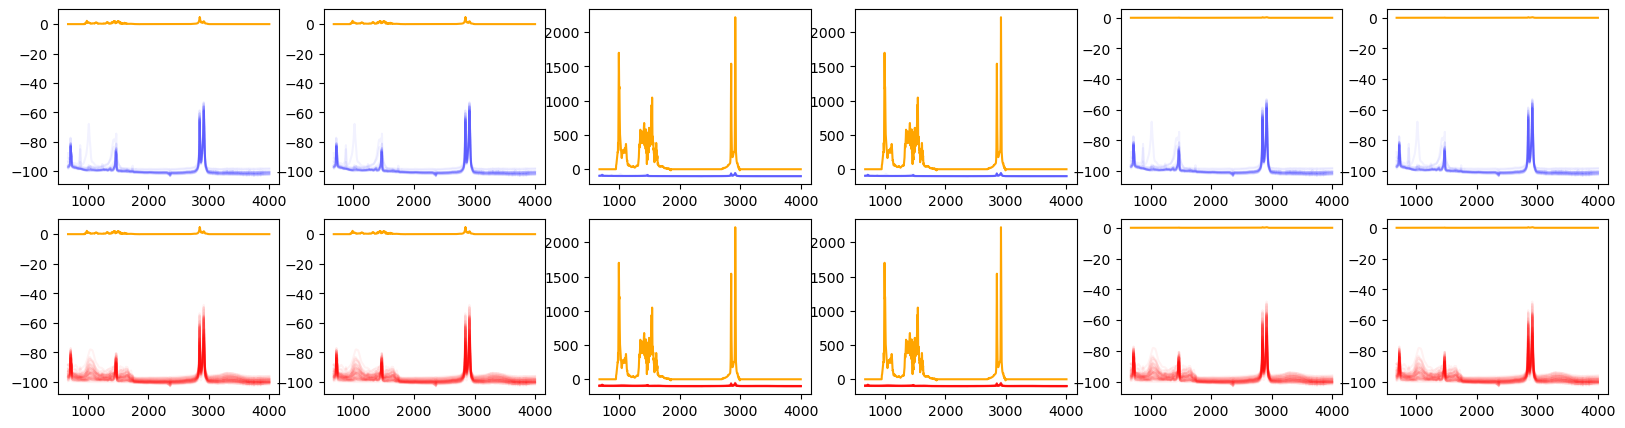

In [12]:
fig, ax = plt.subplots(nrows=2, ncols=6)
fig.set_figheight(5)
fig.set_figwidth(20)

for i in range(6):
    _ = ax[0,i].plot(df_IR_pivot_int.iloc[i,1:].T, label=df_PET_IR_pivot_int.index, c='orange')
    _ = ax[0,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp"').iloc[:, 3:].T, c='blue', alpha=.05)

    _ = ax[1,i].plot(df_IR_pivot_int.iloc[i,1:].T, label=df_PET_IR_pivot_int.index, c='orange')
    _ = ax[1,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp_e"').iloc[:, 3:].T, c='red', alpha=.05)


#_ = plt.legend()

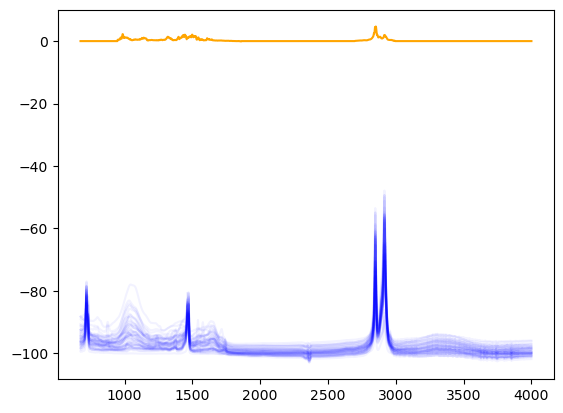

In [13]:
_ = plt.plot(df_IR_pivot_int.iloc[0,1:].T, label=df_IR_pivot_int.index, c='orange')
_ = plt.plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp_e"').iloc[:, 3:].T, c='blue', alpha=.05)
#_ = plt.legend()

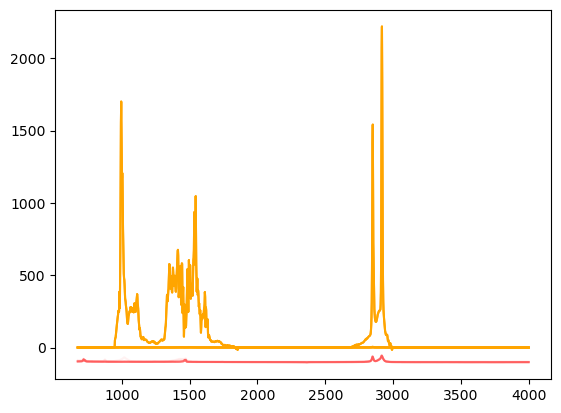

In [14]:
_ = plt.plot(df_IR_pivot_int.iloc[:,1:].T, c='orange')
_ = plt.plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp"').iloc[:, 3:].T, c='red', alpha=.05)
#_ = plt.legend()

In [15]:
pd.DataFrame({'Logistic Reg Pred':clf.model.predict(X_PET),
'Logistic Reg Prob':np.round(clf.model.predict_proba(X_PET)*100).max(1),
'HQI Pred':corr_matching(X_train, y_train, X_PET, r_min=0.7)[0],
'HQI':np.round(corr_matching(X_train, y_train, X_PET, r_min=0.7)[1]*100)})

,Logistic Reg Pred,Logistic Reg Prob,HQI Pred,HQI
172,Polyethylene Terephthalate,7.0,Polyethylene Terephthalate,75.0
255,Polyurethane,6.0,Polypropylene,79.0
316,Polyurethane,25.0,Polyurethane,75.0


In [32]:
#clf.model.classes_[np.argsort(np.round(clf.model.predict_proba(X_PET)*100))][:,-3:]
#np.sort(np.round(clf.model.predict_proba(X_PET)*100))[:,-4:]

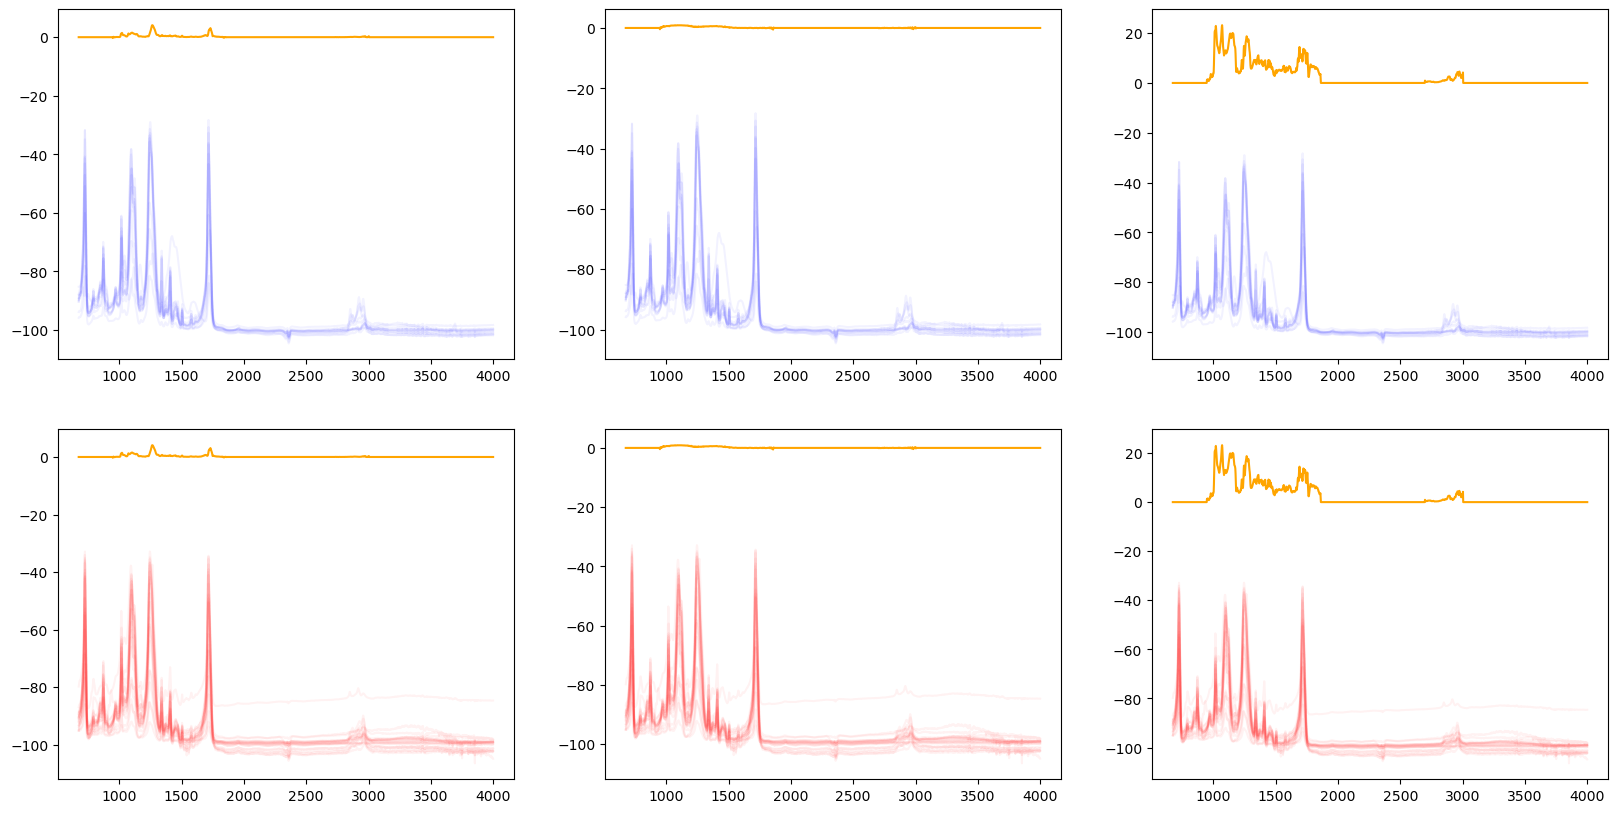

In [17]:
fig, ax = plt.subplots(nrows=2, ncols=3)
fig.set_figheight(10)
fig.set_figwidth(20)

for i in range(3):
    _ = ax[0,i].plot(df_PET_IR_pivot_int.iloc[i,1:].T, label=df_PET_IR_pivot_int.index, c='orange')
    _ = ax[0,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene Terephthalate" and data_source=="flopp"').iloc[:, 3:].T, c='blue', alpha=.05)

    _ = ax[1,i].plot(df_PET_IR_pivot_int.iloc[i,1:].T, label=df_PET_IR_pivot_int.index, c='orange')
    _ = ax[1,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene Terephthalate" and data_source=="flopp_e"').iloc[:, 3:].T, c='red', alpha=.05)


#_ = plt.legend()

In [288]:
def read_spectra(self):
        channels = self.get_channels()

        for c, label in channels.items():
            if label.decode("utf-8") == self.sheet:
                self.data_signal = c
                break
        else:
            self.data_signal = list(channels.keys())[0]

        import h5py
        hdf5_file = h5py.File(self.filename,'r')
        keys = list(hdf5_file.keys())

        hyperspectra = False
        intensities = []
        wavenumbers = []
        x_locs = []
        y_locs = []

        # load measurements
        for meas_name in filter(lambda s: s.startswith('Measurement'), keys):
            hdf5_meas = hdf5_file[meas_name]

            meas_keys = list(hdf5_meas.keys())
            meas_attrs = hdf5_meas.attrs

            # check if this measurement contains the selected data channel
            selected_signal = False
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                if hdf5_chan.attrs.keys().__contains__('DataSignal') and hdf5_chan.attrs['DataSignal'] == self.data_signal:
                    selected_signal = True
                    break
            if not selected_signal:
                continue

            # build range arrays
            spec_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeWavenumberStart'):
                    wn_start = meas_attrs['RangeWavenumberStart'][0]
                    wn_end = meas_attrs['RangeWavenumberEnd'][0]
                    wn_points = meas_attrs['RangeWavenumberPoints'][0]
                    spec_vals = np.linspace(wn_start, wn_end, wn_points)
            except:
                raise IOError("Error reading wavenumber range from " + self.filename)

            pos_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeXStart'):
                    x_start = meas_attrs['RangeXStart'][0]
                    x_points = meas_attrs['RangeXPoints'][0]
                    x_incr = meas_attrs['RangeXIncrement'][0]
                    x_end = x_start + x_incr * (x_points - 1)
                    x_min = min(x_start, x_end)
                    if meas_attrs.keys().__contains__('RangeYStart'):
                        y_start = meas_attrs['RangeYStart'][0]
                        y_points = meas_attrs['RangeYPoints'][0]
                        y_incr = meas_attrs['RangeYIncrement'][0]
                        y_end = y_start + y_incr * (y_points - 1)
                        y_min = min(y_start, y_end)

                        # construct the positions array
                        for iY in range(int(y_points)):
                            y = y_min + iY * abs(y_incr)
                            for iX in range(int(x_points)):
                                x = x_min + iX * abs(x_incr)
                                pos_vals.append([x, y])
                        pos_vals = np.array(pos_vals)
                else:
                    pos_vals = np.array([1])
            except:
                raise IOError("Error reading position data from " + self.filename)

            hyperspectra = pos_vals.shape[0] > 1

            # ignore backgrounds and unchecked data
            if not hyperspectra:
                if meas_attrs.keys().__contains__('IsBackground') and meas_attrs['IsBackground'][0]:
                    continue
                if meas_attrs.keys().__contains__('Checked') and not meas_attrs['Checked'][0]:
                    continue

            if len(wavenumbers) == 0:
                wavenumbers = spec_vals

            if hyperspectra:
                x_len = meas_attrs['RangeXPoints'][0]
                y_len = meas_attrs['RangeYPoints'][0]
                x_locs = pos_vals[:x_len,0]
                y_indices = np.round(np.linspace(0, pos_vals.shape[0] - 1, y_len)).astype(int)
                y_locs = pos_vals[y_indices,1]
            else:
                x_locs.append(meas_attrs['LocationX'][0])
                y_locs.append(meas_attrs['LocationY'][0])

            # load channels
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                chan_attrs = hdf5_chan.attrs

                signal = chan_attrs['DataSignal']
                if signal != self.data_signal:
                    continue

                data = hdf5_chan['Raw_Data']
                if hyperspectra:
                    rows = meas_attrs['RangeYPoints'][0]
                    cols = meas_attrs['RangeXPoints'][0]
                    intensities = np.reshape(data, (rows,cols,data.shape[1])) # organized rows, columns, wavelengths
                    break
                else:
                    intensities.append(data[0,:])

        #intensities = np.array(intensities)
        #features = np.array(wavenumbers)
        intensities = intensities
        features = np.array(wavenumbers)
        x_locs = np.array(x_locs).flatten()
        y_locs = np.array(y_locs).flatten()
        if hyperspectra:
            return _spectra_from_image(intensities, features, x_locs, y_locs)
        else:
            spectra = intensities

            # locations
            x_loc = y_loc = np.arange(len(spectra))
            metas = np.array([x_locs[x_loc], y_locs[y_loc]]).T

            domain = Orange.data.Domain([], None,
                                        metas=[Orange.data.ContinuousVariable.make("map_x"),
                                               Orange.data.ContinuousVariable.make("map_y")]
                                        )
            data = Orange.data.Table.from_numpy(domain, X=np.zeros((len(spectra), 0)),
                                                metas=np.asarray(metas, dtype=object))
            return features, spectra, data
        
Orange.data.io.FileFormat.read_spectra = read_spectra


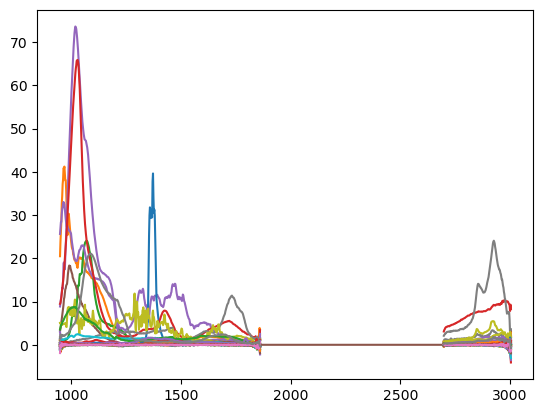

In [289]:
absolute_filename = FileFormat.locate('MNEC_02_057_03-29-2023--04-12-2023_FHS_Back.ptir')
reader = FileFormat.get_reader(absolute_filename)
#reader.select_sheet(None)
spectra = read_spectra(reader)
_ = plt.plot(spectra[0],
             np.array([s if s.shape[0] > 1000 else np.zeros(1029) for s in spectra[1]]).T)

In [290]:
#absolute_filename = FileFormat.locate('MNEC_02_057_03-29-2023--04-12-2023_FHS_Back.ptir')
#reader = FileFormat.get_reader(absolute_filename)
#reader.select_sheet('Raman Intensity')

In [291]:
spectra_data = np.array([s if s.shape[0] > 1000 else np.zeros(1029) for s in spectra[1]])
spectra_df = pd.DataFrame(spectra_data)
spectra_df.columns = spectra[0]

spectra_df = ((spectra_df.T - spectra_df.mean(1)) / spectra_df.std(1)).T
spectra_df_long = spectra_df.reset_index().melt('index')
spectra_df_long.columns = ['file_name','wavelength','intensity']
spectra_df_long['polymer'] = ''
#spectra_df_long = spectra_df_long.query('file_name != 45').reset_index(drop=True)
spectra_df_long = spectra_df_long.query('wavelength > 675 and wavelength < 4000')
spectra_df_long_int = interpol_spect(spectra_df_long, min_wl=674.9918, max_wl=3999.809,n=1725)
#spectra_df_long_int

In [292]:
spectra_df_pivot_int = spectra_df_long_int.pivot(index=['file_name'], 
               columns='wavelength', 
               values='intensity').reset_index()

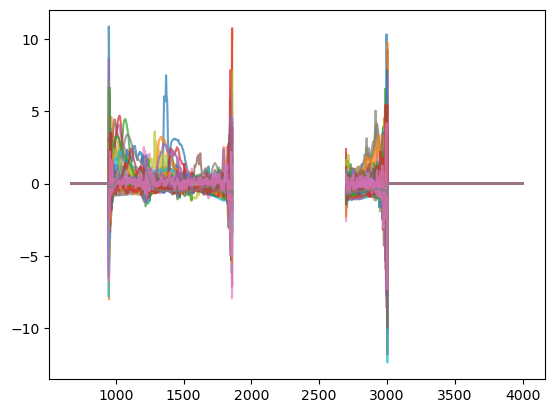

In [293]:
_ = plt.plot(spectra_df_pivot_int.iloc[:,1:].T, alpha=.7)

In [294]:
X_val = np.float32(spectra_df_pivot_int.iloc[:,1:].to_numpy())
X_val[np.isnan(X_val)] = 0
X_val = - X_val

In [295]:
res_table = pd.DataFrame({'log':clf.model.predict(X_val), 
              'log_score':clf.model.predict_proba(X_val).max(1),
              'HQI':corr_matching(X_train, y_train, X_val, r_min=0.7)[0].to_numpy(),
              'HQI_score':corr_matching(X_train, y_train, X_val, r_min=0.7)[1]})#.reset_index(drop=True)

res_table_log = res_table.groupby('log').count().reset_index().loc[:,['log', 'log_score']]
res_table_log.columns = ['polymer', 'n_log']

res_table_hqi = res_table.groupby('HQI').count().reset_index().loc[:,['HQI', 'HQI_score']]
res_table_hqi.columns = ['polymer', 'n_hqi']

res_table_log_score = res_table.groupby('log').mean().reset_index().loc[:,['log', 'log_score']]
res_table_log_score.columns = ['polymer', 'score_log']

res_table_hqi_score = res_table.groupby('HQI').mean().reset_index().loc[:,['HQI', 'HQI_score']]
res_table_hqi_score.columns = ['polymer', 'score_HQI']


res_table = pd.merge(
    np.round(100*pd.merge(res_table_log, res_table_hqi).set_index('polymer') / res_table_log.sum()[1]),
    pd.merge(res_table_log_score, res_table_hqi_score).set_index('polymer'),
    left_index=True,right_index=True
)
res_table

,n_log,n_hqi,score_log,score_HQI
polymer,,,,
Cotton,17.0,12.0,0.649147,0.757143
Polyamide,2.0,2.0,0.160704,0.092972
Polyethylene,16.0,9.0,0.187286,0.329542
Polyethylene Vinyl Acetate,2.0,3.0,0.080955,0.036906
Polypropylene,19.0,45.0,0.336829,0.242887
Polyurethane,14.0,5.0,0.141084,0.121932
Polyvinyl Chloride,12.0,9.0,0.211928,0.239033
Rubber,12.0,9.0,0.140532,0.421375


In [296]:
#spectra[2].to_pandas_dfs()[2]
#plt.scatter(spectra[2].to_pandas_dfs()[2]['map_x'],
#            spectra[2].to_pandas_dfs()[2]['map_y'])

In [297]:
X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
#X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)

X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
#y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)

y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'
n, p = x_train.shape

In [298]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]
df_R = 1-df_R
df_R = np.exp(df_R/.2)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
#smx = 1-smx
smx = (smx / smx.sum(1)[:,None])

In [299]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train,  X_test)[:n_ref, n_ref:]
#df_R = 1-df_R
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx = (smx / smx.sum(1)[:,None])
smx = 1-smx
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_test).to_numpy())}))['id'].to_numpy()


res_dict = defaultdict(list)    

In [300]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train,  X_val)[:n_ref, n_ref:]
#df_R = 1-df_R
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx_val = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx_val = (smx_val / smx_val.sum(1)[:,None])
smx_val = 1-smx_val

In [301]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train,  X_val)[:n_ref, n_ref:]
#df_R = 1-df_R
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train
smx_val = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx_val = (smx_val / smx_val.sum(1)[:,None])
smx_val = 1-smx_val
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_test).to_numpy())}))['id'].to_numpy()

res_dict = defaultdict(list)    

alpha = 0.35
    

# Problem setup
n=195 # number of calibration points
#alpha = alpha # 1-alpha is the desired coverage
# Set RAPS regularization parameters (larger lam_reg and smaller k_reg leads to smaller sets)
lam_reg = 2
k_reg = 2
disallow_zero_sets = True # Set this to False in order to see the coverage upper bound hold
rand = True # Set this to True in order to see the coverage upper bound hold
reg_vec = np.array(k_reg*[0,] + (smx.shape[1]-k_reg)*[lam_reg,])[None,:]


# Split the softmax scores into calibration and validation sets (save the shuffling)
idx = np.array([1] * n + [0] * (smx.shape[0]-n)) > 0
np.random.shuffle(idx)
#cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_smx, val_smx = smx, smx_val
#cal_labels, val_labels = labels[idx], labels[~idx]
cal_labels = labels

# Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
cal_pi = cal_smx.argsort(1)[:,::-1]; 
cal_srt = np.take_along_axis(cal_smx,cal_pi,axis=1)
cal_srt_reg = cal_srt + reg_vec
cal_L = np.where(cal_pi == cal_labels[:,None])[1]

cal_scores = cal_srt_reg[np.arange(n),cal_L]
#cal_scores = cal_srt_reg.cumsum(axis=1)[np.arange(n),cal_L] - np.random.rand(n)*cal_srt_reg[np.arange(n),cal_L]
# Get the score quantile
qhat = np.quantile(cal_scores, np.ceil((n+1)*(1-alpha))/n, interpolation='higher')
# Deploy
n_val = val_smx.shape[0]
val_pi = val_smx.argsort(1)[:,::-1]
val_srt = np.take_along_axis(val_smx,val_pi,axis=1)
val_srt_reg = val_srt + reg_vec
val_srt_reg_cumsum = val_srt_reg.cumsum(axis=1)
#indicators = (val_srt_reg.cumsum(axis=1) - np.random.rand(n_val,1)*val_srt_reg) <= qhat if rand else val_srt_reg.cumsum(axis=1) - val_srt_reg <= qhat
indicators = val_srt_reg <= qhat
if disallow_zero_sets: indicators[:,0] = True
prediction_sets = np.take_along_axis(indicators,val_pi.argsort(axis=1),axis=1)

# Calculate empirical coverage
#empirical_coverage = prediction_sets[np.arange(n_val),val_labels].mean()

#print(f"The empirical coverage is: {empirical_coverage}")
#print(f"The quantile is: {qhat}")

#cov[i] = empirical_coverage
prediction_sets.sum(1).mean()
    

2.6724137931034484

In [302]:
labels_df = pd.DataFrame({'id':range(15), 'polymer':np.unique((y_test).to_numpy())})
#labels_df

In [303]:
#import itertools

list_conf_pred = list(itertools.chain.from_iterable(
[labels_df.loc[prediction_sets[i],'polymer'].to_list() for i in range(58)]
    ))

np.round(pd.DataFrame({'polymer':list_conf_pred,
'n':1}).groupby('polymer').sum() / len(list_conf_pred)*100)

,n
polymer,
Cellulose Acetate,3.0
Cotton,11.0
Ethylene Acrylic Acid,12.0
Polyamide,14.0
Polycarbonate,10.0
Polyethylene,13.0
Polyethylene Terephthalate,2.0
Polymethyl Methacrylate,9.0
Polypropylene,12.0


In [304]:
res_table

,n_log,n_hqi,score_log,score_HQI
polymer,,,,
Cotton,17.0,12.0,0.649147,0.757143
Polyamide,2.0,2.0,0.160704,0.092972
Polyethylene,16.0,9.0,0.187286,0.329542
Polyethylene Vinyl Acetate,2.0,3.0,0.080955,0.036906
Polypropylene,19.0,45.0,0.336829,0.242887
Polyurethane,14.0,5.0,0.141084,0.121932
Polyvinyl Chloride,12.0,9.0,0.211928,0.239033
Rubber,12.0,9.0,0.140532,0.421375


In [305]:
#pd.DataFrame({'prediction_sets':['_'.join(labels_df.loc[prediction_sets[i],'polymer'].to_list()) for i in range(58)]})
#['_'.join(labels_df.loc[prediction_sets[i],'polymer'].to_list()) for i in range(58)]

In [306]:
idx_range = np.logical_or(
    np.logical_and(
        wl_list > (spectra[0]).min(),
        wl_list < (spectra[0][np.where(np.isnan(spectra[1][0]))]).min(),
    ),
    np.logical_and(
        wl_list > (spectra[0][np.where(np.isnan(spectra[1][0]))]).max(),
        wl_list < (spectra[0]).max(),
    )
)

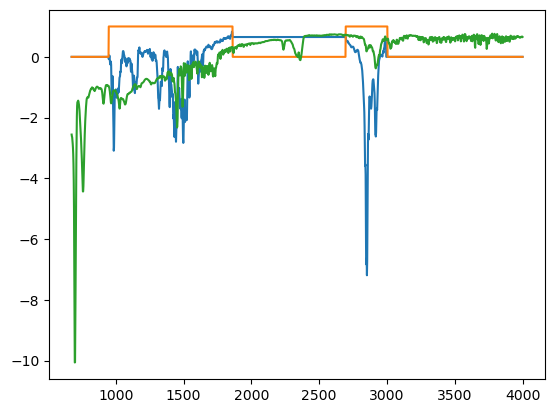

In [307]:
plt.plot(wl_list,X_PE[0])
plt.plot(wl_list,idx_range)
plt.plot(X_train.iloc[0,:])

In [308]:
#X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)

X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
#y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)

y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
x_train = x_train[:, idx_range]

x_test = X_test.to_numpy()
x_test = x_test[:, idx_range]

y_train_ = y_train.to_numpy()
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'
n, p = x_train.shape

In [353]:
X_PE = df_IR_pivot_int.iloc[:,1:].to_numpy()
X_PE[np.isnan(X_PE)] = 0
X_PE = - X_PE
X_PE = X_PE[:, idx_range]

X_PET = df_PET_IR_pivot_int.iloc[:,1:].to_numpy()
X_PET[np.isnan(X_PET)] = 0
X_PET = - X_PET
X_PET = X_PET[:, idx_range] #(np.power(X_val,2) > 0.000000001)[0]

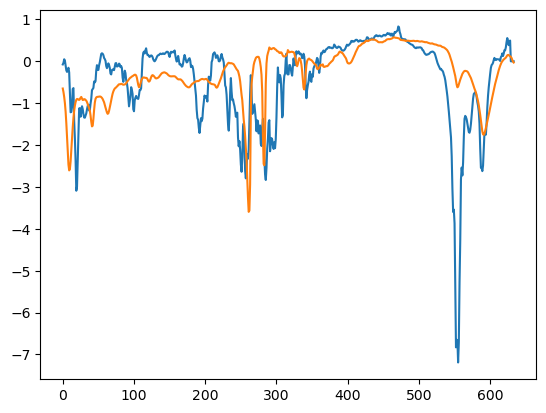

In [354]:
plt.plot(X_PE[0])
#plt.plot(wl_list,idx_range)
plt.plot(x_train[0,:])

In [355]:
(idx_range).shape

(1725,)

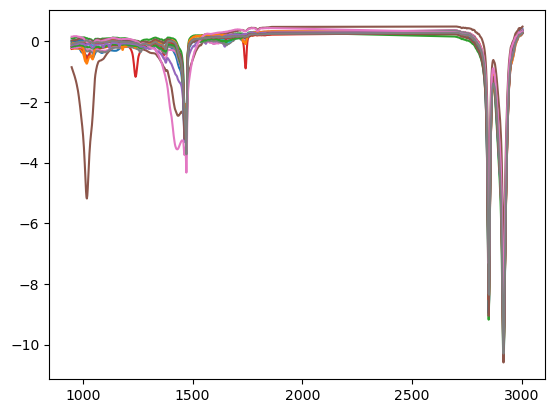

In [356]:
plt.plot(df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp"').iloc[:, 3:].T.iloc[idx_range,:])

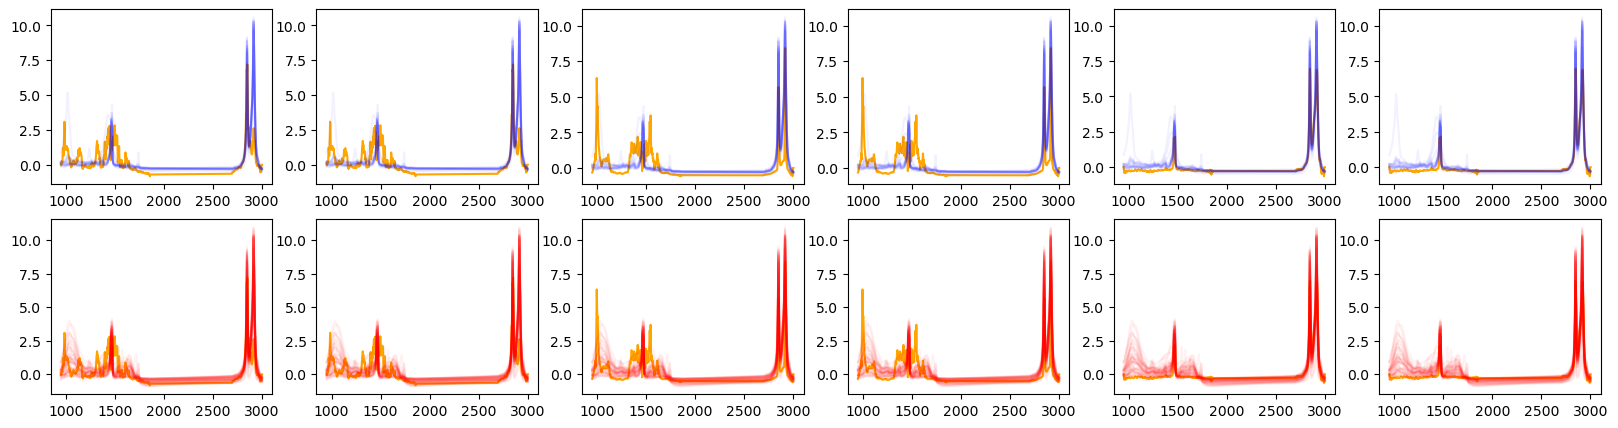

In [357]:
fig, ax = plt.subplots(nrows=2, ncols=6)
fig.set_figheight(5)
fig.set_figwidth(20)

for i in range(6):
    _ = ax[0,i].plot(df_IR_pivot_int.iloc[i,1:].T[idx_range], c='orange')
    _ = ax[0,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp"').iloc[:, 3:].T.iloc[idx_range,:], c='blue', alpha=.05)

    _ = ax[1,i].plot(df_IR_pivot_int.iloc[i,1:].T[idx_range], c='orange')
    _ = ax[1,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp_e"').iloc[:, 3:].T.iloc[idx_range,:], c='red', alpha=.05)


#_ = plt.legend()

In [358]:
clf = model_logReg(C=7)
clf.train_data(x_train, y_train_)
clf.fit()
clf.score(x_test, y_test)

1.0

(6, 634)

In [359]:
pd.DataFrame({'Logistic Reg Pred':clf.model.predict(X_PE),
'Logistic Reg Prob':np.round(clf.model.predict_proba(X_PE)*100).max(1),
'HQI Pred':corr_matching(x_train, y_train, X_PE, r_min=0.7)[0],
'HQI':np.round(corr_matching(x_train, y_train, X_PE, r_min=0.7)[1]*100)})

,Logistic Reg Pred,Logistic Reg Prob,HQI Pred,HQI
112,Polyethylene,96.0,Polyethylene,68.0
112,Polyethylene,96.0,Polyethylene,68.0
94,Polyethylene,85.0,Polyethylene,68.0
94,Polyethylene,85.0,Polyethylene,68.0
111,Polyethylene,98.0,Polyethylene,98.0
111,Polyethylene,98.0,Polyethylene,98.0


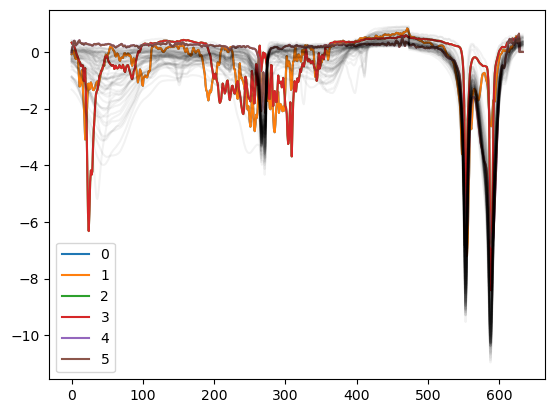

In [159]:
_ = plt.plot(X_PE.T, label=df_IR_pivot_int.index)
_ = plt.plot(x_train[y_train_ == "Polyethylene",:].T, c='black', alpha=.05)
#_ = plt.plot(-df_flopp_pivot.query('polymer == "Polyethylene"').iloc[:, 3:].T, c='black', alpha=.05)
_ = plt.legend()

In [329]:
pd.DataFrame({'Logistic Reg Pred':clf.model.predict(X_PET),
'Logistic Reg Prob':np.round(clf.model.predict_proba(X_PET)*100).max(1),
'HQI Pred':corr_matching(x_train, y_train, X_PET, r_min=0.7)[0],
'HQI':np.round(corr_matching(x_train, y_train, X_PET, r_min=0.7)[1]*100)})

,Logistic Reg Pred,Logistic Reg Prob,HQI Pred,HQI
157,Polyethylene Terephthalate,97.0,Polyethylene Terephthalate,78.0
374,Cotton,57.0,Rubber,84.0
318,Polyurethane,57.0,Polyurethane,73.0


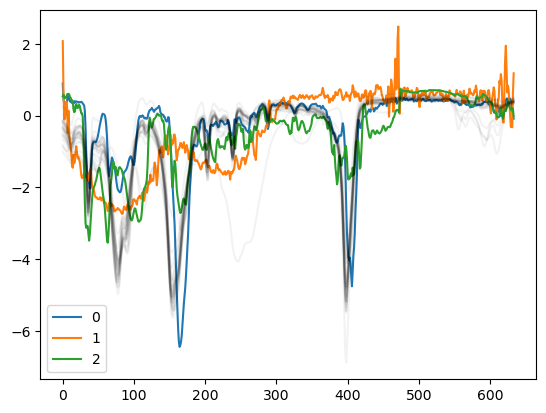

In [213]:
_ = plt.plot(X_PET.T, label=df_PET_IR_pivot_int.index)
_ = plt.plot(x_train[y_train_ == "Polyethylene Terephthalate",:].T, c='black', alpha=.05)
#_ = plt.plot(-df_flopp_pivot.query('polymer == "Polyethylene"').iloc[:, 3:].T, c='black', alpha=.05)
_ = plt.legend()

In [233]:
x_train[y_train_ == "Polyethylene Terephthalate",:].T[:,0]

array([-2.34076861e-01, -2.44307968e-01, -2.56569944e-01, -2.70926758e-01,
       -2.86986057e-01, -3.09837377e-01, -3.36682198e-01, -3.70652544e-01,
       -4.05574780e-01, -4.43131771e-01, -4.79269457e-01, -5.08747327e-01,
       -5.26785464e-01, -5.35057350e-01, -5.32994923e-01, -5.26909142e-01,
       -5.17057596e-01, -5.08169029e-01, -4.99576434e-01, -4.95061782e-01,
       -4.91927200e-01, -4.94718044e-01, -5.03697024e-01, -5.19503850e-01,
       -5.40514509e-01, -5.70130558e-01, -6.08355407e-01, -6.60048299e-01,
       -7.23934077e-01, -8.07040179e-01, -9.27183825e-01, -1.10915850e+00,
       -1.38457700e+00, -1.82315671e+00, -2.38785326e+00, -2.77574656e+00,
       -2.70580058e+00, -2.27721742e+00, -1.80524481e+00, -1.49631144e+00,
       -1.36316204e+00, -1.33725461e+00, -1.35464366e+00, -1.38681428e+00,
       -1.42436019e+00, -1.46674657e+00, -1.51041493e+00, -1.54878734e+00,
       -1.57072174e+00, -1.56556993e+00, -1.52397850e+00, -1.45153766e+00,
       -1.35878813e+00, -

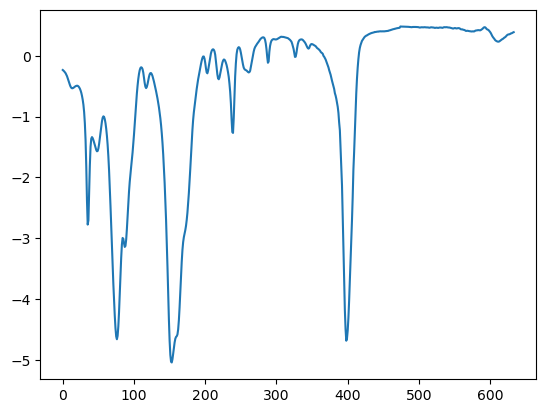

In [234]:
plt.plot(x_train[y_train_ == "Polyethylene Terephthalate",:].T[:,0])

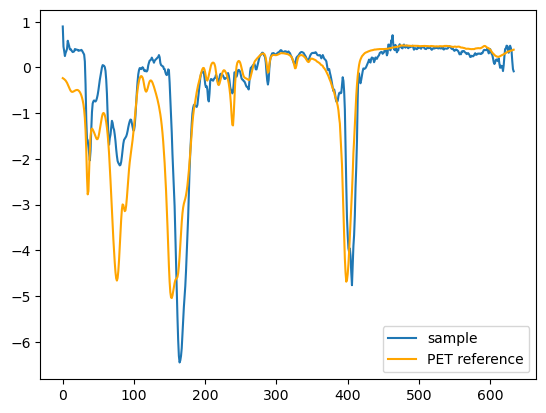

In [237]:
_ = plt.plot(X_PET.T[:,0], label='sample')
_ = plt.plot(x_train[y_train_ == "Polyethylene Terephthalate",:].T[:,0], c='orange', label='PET reference')
#_ = plt.plot(-df_flopp_pivot.query('polymer == "Polyethylene"').iloc[:, 3:].T, c='black', alpha=.05)
_ = plt.legend()

In [209]:
#clf.model.classes_[np.argsort(np.round(clf.model.predict_proba(X_PET)*100))][:,-3:]
#np.sort(np.round(clf.model.predict_proba(X_PET)*100))[:,-4:]
pd.DataFrame(clf.model.classes_[np.argsort(np.round(clf.model.predict_proba(X_PET)*100))][:,-3:])

,0,1,2
0,Polyethylene Adipate,Polyvinyl Chloride,Polyethylene Terephthalate
1,Polystyrene,Polyurethane,Cotton
2,Polymethyl Methacrylate,Polyethylene Terephthalate,Polyurethane


In [370]:
X_val = np.float32(spectra_df_pivot_int.iloc[:,1:].to_numpy())
X_val[np.isnan(X_val)] = 0
X_val = - X_val
X_val = X_val[:, idx_range]

In [371]:
res_table = pd.DataFrame({'log':clf.model.predict(X_val), 
              'log_score':clf.model.predict_proba(X_val).max(1),
              'HQI':corr_matching(x_train, y_train, X_val, r_min=0.7)[0].to_numpy(),
              'HQI_score':corr_matching(x_train, y_train, X_val, r_min=0.7)[1]})#.reset_index(drop=True)

In [372]:
(res_table['log'] == res_table['HQI']).mean()

0.4827586206896552

In [404]:
res_table = pd.DataFrame({'Logistic Reg Pred':clf.model.predict(X_val), 
              'Logistic Reg Prob':clf.model.predict_proba(X_val).max(1),
              'HQI Pred':corr_matching(x_train, y_train, X_val, r_min=0.7)[0].to_numpy(),
              'HQI':corr_matching(x_train, y_train, X_val, r_min=0.7)[1]})#.reset_index(drop=True)

res_table_log = res_table.groupby('Logistic Reg Pred').count().reset_index().loc[:,['Logistic Reg Pred', 'Logistic Reg Prob']]
res_table_log.columns = ['polymer', 'Logistic (%)']

res_table_hqi = res_table.groupby('HQI Pred').count().reset_index().loc[:,['HQI Pred', 'HQI']]
res_table_hqi.columns = ['polymer', 'HQI (%)']

res_table_log_score = res_table.groupby('Logistic Reg Pred').mean().reset_index().loc[:,['Logistic Reg Pred', 'Logistic Reg Prob']]
res_table_log_score.columns = ['polymer', 'Logistic Reg Prob']

res_table_hqi_score = res_table.groupby('HQI Pred').mean().reset_index().loc[:,['HQI Pred', 'HQI']]
res_table_hqi_score.columns = ['polymer', 'HQI']

res_table['same'] = res_table['Logistic Reg Pred'] == res_table['HQI Pred']

res_table_ = pd.merge(
    np.round(100*pd.merge(res_table_log, res_table_hqi).set_index('polymer') / res_table_log.sum()[1]),
    
    np.round(100*pd.merge(res_table_log_score, res_table_hqi_score).set_index('polymer')),
    left_index=True,right_index=True
)

res_table_ = pd.merge(
    res_table_,
    np.round(100*res_table.groupby('Logistic Reg Pred').mean()[['same']]),
    left_index=True,right_index=True
)
res_table_


,Logistic (%),HQI (%),Logistic Reg Prob,HQI,same
polymer,,,,,
Acrylonitrile Butadiene Styrene,9.0,2.0,16.0,6.0,20.0
Cotton,9.0,3.0,67.0,93.0,40.0
Polycarbonate,2.0,2.0,11.0,7.0,100.0
Polyethylene,9.0,10.0,27.0,34.0,60.0
Polyethylene Vinyl Acetate,2.0,3.0,11.0,5.0,100.0
Polypropylene,16.0,31.0,50.0,25.0,89.0
Polystyrene,26.0,19.0,50.0,52.0,47.0
Polyurethane,3.0,3.0,23.0,16.0,50.0
Polyvinyl Chloride,7.0,9.0,37.0,38.0,25.0


In [386]:
#(np.round(100*pd.merge(res_table_log, res_table_hqi).set_index('polymer') / res_table_log.sum()[1])['Logistic (%)'] == 
np.round(100*pd.merge(res_table_log, res_table_hqi).set_index('polymer') / res_table_log.sum()[1])['HQI (%)']


polymer
Acrylonitrile Butadiene Styrene     2.0
Cotton                              3.0
Polycarbonate                       2.0
Polyethylene                       10.0
Polyethylene Vinyl Acetate          3.0
Polypropylene                      31.0
Polystyrene                        19.0
Polyurethane                        3.0
Polyvinyl Chloride                  9.0
Rubber                             16.0
Name: HQI (%), dtype: float64

In [174]:
X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
#X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)

X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
#y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)

y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
x_train = x_train[:, idx_range]

x_test = X_test.to_numpy()
x_test = x_test[:, idx_range]

y_train_ = y_train.to_numpy()
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'
n, p = x_train.shape

In [207]:
n_ref = X_train.shape[0]
df_R = np.corrcoef(X_train.loc[:, idx_range],  X_test.loc[:, idx_range])[:n_ref, n_ref:]
#df_R = 1-df_R
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train_
smx = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx = (smx / smx.sum(1)[:,None])
smx = 1-smx
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_test).to_numpy())}))['id'].to_numpy()


res_dict = defaultdict(list)  

n_ref = X_train.loc[:, idx_range].shape[0]
df_R = np.corrcoef(X_train.loc[:, idx_range],  X_val)[:n_ref, n_ref:]
#df_R = 1-df_R
df_R = np.exp(df_R/.1)
df_R = pd.DataFrame(df_R)
df_R['polymer_ref'] = y_train_
smx_val = (df_R.melt(id_vars=['polymer_ref']).
         groupby(['variable','polymer_ref']).
         max().
         reset_index().pivot(index='variable', columns='polymer_ref', values='value')).to_numpy()
#sns.heatmap(pd.DataFrame(smx))
#pd.DataFrame(smx)
smx_val = (smx_val / smx_val.sum(1)[:,None])
smx_val = 1-smx_val
labels = y_test.reset_index().merge(pd.DataFrame({'id':range(15), 'polymer':np.unique((y_test).to_numpy())}))['id'].to_numpy()

res_dict = defaultdict(list)    

alpha = 0.99
    

# Problem setup
n=195 # number of calibration points
#alpha = alpha # 1-alpha is the desired coverage
# Set RAPS regularization parameters (larger lam_reg and smaller k_reg leads to smaller sets)
lam_reg = 2
k_reg = 4
disallow_zero_sets = True # Set this to False in order to see the coverage upper bound hold
rand = True # Set this to True in order to see the coverage upper bound hold
reg_vec = np.array(k_reg*[0,] + (smx_val.shape[1]-k_reg)*[lam_reg,])[None,:]


# Split the softmax scores into calibration and validation sets (save the shuffling)
idx = np.array([1] * n + [0] * (smx_val.shape[0]-n)) > 0
np.random.shuffle(idx)
#cal_smx, val_smx = smx[idx,:], smx[~idx,:]
cal_smx, val_smx = smx, smx_val
#cal_labels, val_labels = labels[idx], labels[~idx]
cal_labels = labels

# Get scores. calib_X.shape[0] == calib_Y.shape[0] == n
cal_pi = cal_smx.argsort(1)[:,::-1]; 
cal_srt = np.take_along_axis(cal_smx,cal_pi,axis=1)
cal_srt_reg = cal_srt + reg_vec
cal_L = np.where(cal_pi == cal_labels[:,None])[1]

cal_scores = cal_srt_reg[np.arange(n),cal_L]
#cal_scores = cal_srt_reg.cumsum(axis=1)[np.arange(n),cal_L] - np.random.rand(n)*cal_srt_reg[np.arange(n),cal_L]
# Get the score quantile
qhat = np.quantile(cal_scores, np.ceil((n+1)*(1-alpha))/n, interpolation='higher')
# Deploy
n_val = val_smx.shape[0]
val_pi = val_smx.argsort(1)[:,::-1]
val_srt = np.take_along_axis(val_smx,val_pi,axis=1)
val_srt_reg = val_srt + reg_vec
val_srt_reg_cumsum = val_srt_reg.cumsum(axis=1)
#indicators = (val_srt_reg.cumsum(axis=1) - np.random.rand(n_val,1)*val_srt_reg) <= qhat if rand else val_srt_reg.cumsum(axis=1) - val_srt_reg <= qhat
indicators = val_srt_reg <= qhat
if disallow_zero_sets: indicators[:,0] = True
prediction_sets = np.take_along_axis(indicators,val_pi.argsort(axis=1),axis=1)

# Calculate empirical coverage
#empirical_coverage = prediction_sets[np.arange(n_val),val_labels].mean()

#print(f"The empirical coverage is: {empirical_coverage}")
#print(f"The quantile is: {qhat}")

#cov[i] = empirical_coverage
prediction_sets.sum(1).mean()
    

3.189655172413793

In [208]:
list_conf_pred = list(itertools.chain.from_iterable(
[labels_df.loc[prediction_sets[i],'polymer'].to_list() for i in range(58)]
    ))

np.round(pd.DataFrame({'polymer':list_conf_pred,
'n':1}).groupby('polymer').sum() / len(list_conf_pred)*100)

,n
polymer,
Acrylonitrile Butadiene Styrene,3.0
Cellulose Acetate,2.0
Cotton,11.0
Ethylene Acrylic Acid,8.0
Polyamide,15.0
Polycarbonate,10.0
Polyethylene,12.0
Polyethylene Terephthalate,5.0
Polyethylene Vinyl Acetate,2.0


In [185]:
res_table

,n_log,n_hqi,score_log,score_HQI
polymer,,,,
Acrylonitrile Butadiene Styrene,9.0,2.0,0.157794,0.062025
Cotton,9.0,3.0,0.670349,0.926653
Polycarbonate,2.0,2.0,0.112798,0.068886
Polyethylene,9.0,10.0,0.272905,0.341264
Polyethylene Vinyl Acetate,2.0,3.0,0.112618,0.046553
Polypropylene,16.0,31.0,0.498206,0.250266
Polystyrene,26.0,19.0,0.500953,0.522821
Polyurethane,3.0,3.0,0.232548,0.155033
Polyvinyl Chloride,7.0,9.0,0.365582,0.382102


In [ ]:
df_IR = df_PE.iloc[:,5:]
df_IR.columns = [
    'wavelength', 'particle_1', 'particle_2', 'particle_3', 'particle_4', 'particle_5', 'particle_6'
]
df_IR = df_IR.astype('float32').set_index('wavelength')
df_IR = ((df_IR - df_IR.mean()) / df_IR.std()).reset_index()
df_IR_long = df_IR.melt(id_vars='wavelength')
df_IR_long.columns = ['wavelength','file_name','intensity']
df_IR_long['polymer'] = ''
df_IR_long_int = interpol_spect(df_IR_long, min_wl=674.9918, max_wl=3999.809,n=1725)


df_PET_IR = df_PET.iloc[:,:4]
df_PET_IR.columns = [
    'wavelength', 'particle_1', 'particle_2', 'particle_3'
]
df_PET_IR = df_PET_IR.astype('float32').set_index('wavelength')
df_PET_IR = ((df_PET_IR - df_PET_IR.mean()) / df_PET_IR.std()).reset_index()
df_PET_IR_long = df_PET_IR.melt(id_vars='wavelength')
df_PET_IR_long.columns = ['wavelength','file_name','intensity']
df_PET_IR_long['polymer'] = ''
df_PET_IR_long_int = interpol_spect(df_PET_IR_long, min_wl=674.9918, max_wl=3999.809,n=1725)


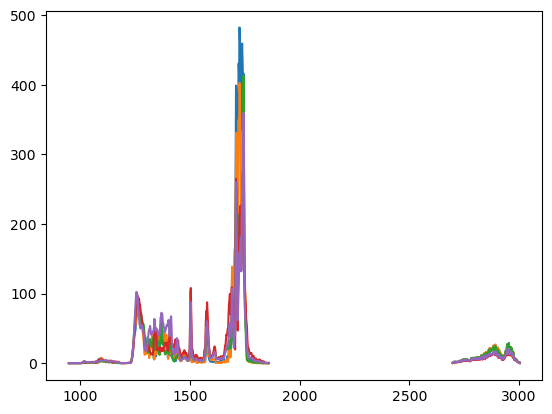

In [343]:
plt.plot(df_PET_avg.set_index('wavelength'))

In [350]:
df_PET_avg = Orange.data.Table('OPTIR/MEC_02_059_PET_signal_noise_study.ptir')
df_PET_avg = (
    df_PET_avg.
    X_df.T.
    reset_index().
    astype('float32'))
df_PET_avg.columns = [
    'wavelength', 'particle_1', 'particle_2', 'particle_3', 'particle_4', 'particle_5'
]


df_PET_avg = df_PET_avg.astype('float32').set_index('wavelength')
df_PET_avg = ((df_PET_avg - df_PET_avg.mean()) / df_PET_avg.std()).reset_index()
df_PET_avg_long = df_PET_avg.melt(id_vars='wavelength')
df_PET_avg_long.columns = ['wavelength','file_name','intensity']
df_PET_avg_long['polymer'] = ''
df_PET_avg_long_int = interpol_spect(df_PET_avg_long, min_wl=674.9918, max_wl=3999.809,n=1725)


df_PE_avg = Orange.data.Table('OPTIR/MEC_02_059_PE_53-63um_signal_noise_study.ptir')
df_PE_avg = (
    df_PE_avg.
    X_df.T.
    reset_index().
    astype('float32'))
df_PE_avg.columns = [
    'wavelength', 'particle_1', 'particle_2', 'particle_3', 'particle_4', 'particle_5'
]

df_PE_avg = df_PE_avg.astype('float32').set_index('wavelength')
df_PE_avg = ((df_PE_avg - df_PE_avg.mean()) / df_PE_avg.std()).reset_index()
df_PE_avg_long = df_PE_avg.melt(id_vars='wavelength')
df_PE_avg_long.columns = ['wavelength','file_name','intensity']
df_PE_avg_long['polymer'] = ''
df_PE_avg_long_int = interpol_spect(df_PE_avg_long, min_wl=674.9918, max_wl=3999.809,n=1725)
df_PE_avg_long_int

,wavelength,intensity,polymer,file_name
0,674.991800,0.0,,particle_1
1,676.920348,0.0,,particle_1
2,678.848897,0.0,,particle_1
3,680.777445,0.0,,particle_1
4,682.705993,0.0,,particle_1
...,...,...,...,...
8620,3992.094807,0.0,,particle_5
8621,3994.023355,0.0,,particle_5
8622,3995.951903,0.0,,particle_5
8623,3997.880452,0.0,,particle_5


In [361]:
df_PE_avg_pivot_int = df_PE_avg_long_int.pivot(index=['file_name'], 
               columns='wavelength', 
               values='intensity').reset_index()

df_PET_avg_pivot_int = df_PET_avg_long_int.pivot(index=['file_name'], 
               columns='wavelength', 
               values='intensity').reset_index()


X_PE_avg = df_PE_avg_pivot_int.iloc[:,1:].to_numpy()
X_PE_avg[np.isnan(X_PE_avg)] = 0
X_PE_avg = - X_PE_avg
X_PE_avg = X_PE_avg[:, idx_range]


X_PET_avg = df_PET_avg_pivot_int.iloc[:,1:].to_numpy()
X_PET_avg[np.isnan(X_PET_avg)] = 0
X_PET_avg = - X_PET_avg
X_PET_avg = X_PET_avg[:, idx_range]

In [362]:
pd.DataFrame({'Logistic Reg Pred':clf.model.predict(X_PE_avg),
'Logistic Reg Prob':np.round(clf.model.predict_proba(X_PE_avg)*100).max(1),
'HQI Pred':corr_matching(x_train, y_train, X_PE_avg, r_min=0.7)[0],
'HQI':np.round(corr_matching(x_train, y_train, X_PE_avg, r_min=0.7)[1]*100)})

,Logistic Reg Pred,Logistic Reg Prob,HQI Pred,HQI
90,Polyethylene,54.0,Polyethylene,87.0
111,Polyethylene,95.0,Polyethylene,90.0
135,Polyethylene,96.0,Polyethylene,86.0
135,Polyethylene,93.0,Polyethylene,95.0
133,Polyethylene,96.0,Polyethylene,96.0


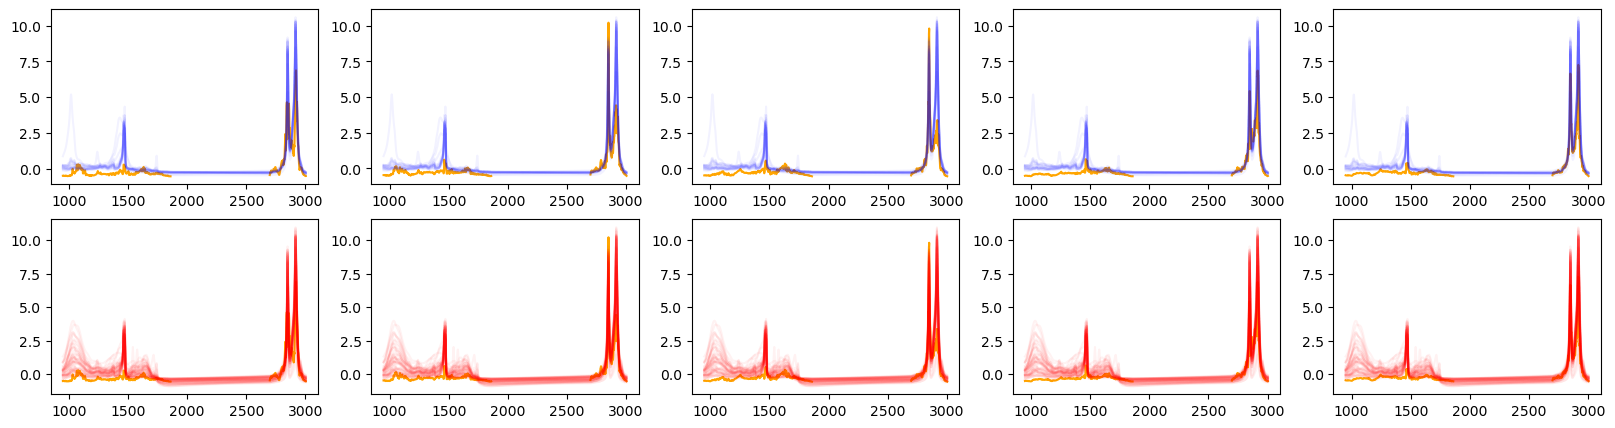

In [365]:
fig, ax = plt.subplots(nrows=2, ncols=5)
fig.set_figheight(5)
fig.set_figwidth(20)

for i in range(5):
    _ = ax[0,i].plot(df_PE_avg_pivot_int.iloc[i,1:].T[idx_range], c='orange')
    _ = ax[0,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp"').iloc[:, 3:].T.iloc[idx_range,:], c='blue', alpha=.05)

    _ = ax[1,i].plot(df_PE_avg_pivot_int.iloc[i,1:].T[idx_range], c='orange')
    _ = ax[1,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene" and data_source=="flopp_e"').iloc[:, 3:].T.iloc[idx_range,:], c='red', alpha=.05)


#_ = plt.legend()

In [363]:
pd.DataFrame({'Logistic Reg Pred':clf.model.predict(X_PET_avg),
'Logistic Reg Prob':np.round(clf.model.predict_proba(X_PET_avg)*100).max(1),
'HQI Pred':corr_matching(x_train, y_train, X_PE_avg, r_min=0.7)[0],
'HQI':np.round(corr_matching(x_train, y_train, X_PET_avg, r_min=0.7)[1]*100)})

,Logistic Reg Pred,Logistic Reg Prob,HQI Pred,HQI
90,Polyethylene Terephthalate,48.0,Polyethylene,50.0
111,Polyethylene Terephthalate,57.0,Polyethylene,51.0
135,Polyethylene Terephthalate,54.0,Polyethylene,50.0
135,Polyethylene Terephthalate,55.0,Polyethylene,49.0
133,Polyethylene Terephthalate,42.0,Polyethylene,46.0


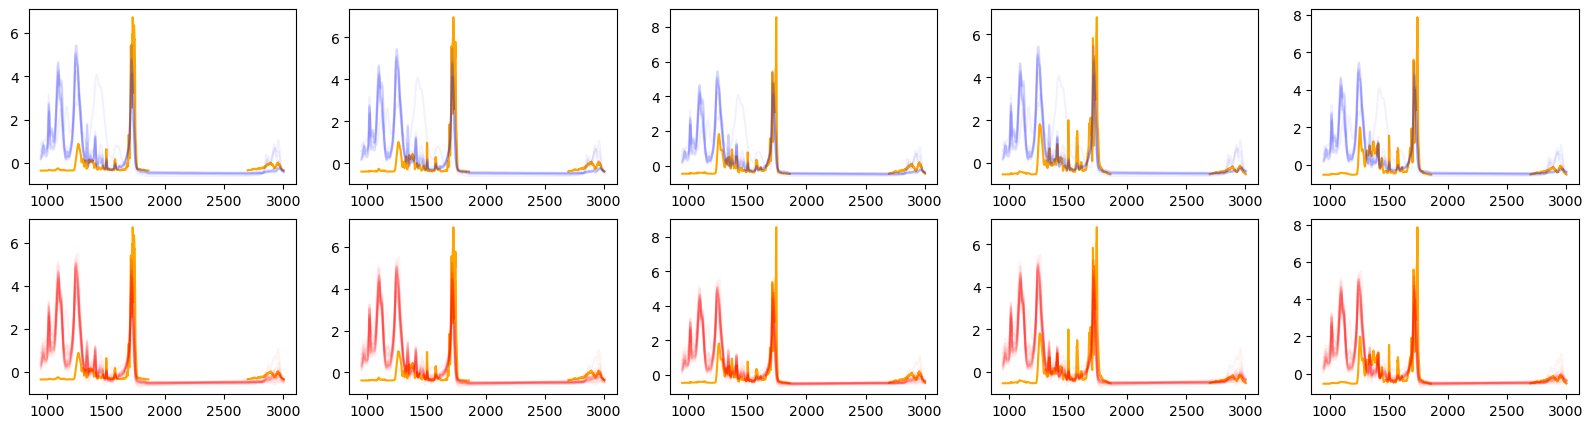

In [366]:
fig, ax = plt.subplots(nrows=2, ncols=5)
fig.set_figheight(5)
fig.set_figwidth(20)

for i in range(5):
    _ = ax[0,i].plot(df_PET_avg_pivot_int.iloc[i,1:].T[idx_range], c='orange')
    _ = ax[0,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene Terephthalate" and data_source=="flopp"').iloc[:, 3:].T.iloc[idx_range,:], c='blue', alpha=.05)

    _ = ax[1,i].plot(df_PET_avg_pivot_int.iloc[i,1:].T[idx_range], c='orange')
    _ = ax[1,i].plot(-df_flopp_pivot.query('polymer == "Polyethylene Terephthalate" and data_source=="flopp_e"').iloc[:, 3:].T.iloc[idx_range,:], c='red', alpha=.05)


#_ = plt.legend()